Clase 011 · `011_matplotlib2` · Clasifica cada hora del año promedio en frío (menos de
18 °C), confort (18 a 23 °C) y calor (más de 23 °C) con `pd.cut`, cuenta la fracción de
cada categoría con `crosstab` y la dibuja como barra apilada. Después comprueba el
resultado por otro camino: máscaras booleanas y una gráfica de puntos por color.

::: {.callout-important title="Datos"}
`anio_promedio-2020-2026.parquet` lo produce la libreta `003_AnioPromedio` en
`clases/011_matplotlib2/data/003_results/`; córrela primero.
:::

## Librerías

`pandas` y `matplotlib`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Leer el año promedio

El mismo archivo del heatmap; `info()` quedó comentado.

In [2]:
f = "../data/003_results/anio_promedio-2020-2026.parquet"
esolmet = pd.read_parquet(f)
# esolmet.info()

## Los límites de las categorías

`niveles` son los cuatro bordes de tres intervalos: de menos infinito a 18, de 18 a 23 y
de 23 a infinito. `etiquetas` les pone nombre. Declararlos en variables deja a la vista
la decisión de dónde empieza el confort.

In [3]:
niveles = [-float("inf"), 18, 23, float("inf")]
etiquetas = ["frio","confort","calor"]
niveles,etiquetas

([-inf, 18, 23, inf], ['frio', 'confort', 'calor'])

Las dos últimas horas del año, para ver con qué columnas trabajamos.

In [4]:
esolmet.tail(2)

variable,dhi,dni,ghi,p_atm,rain_acc,rh,tdb,uv,wd,ws
date,,,,,,,,,,
2024-12-31 22:00:00,0.0,0.0,0.0,860.360770,0.502667,50.749028,19.289267,0.003012,299.731850,1.723550
2024-12-31 23:00:00,0.0,0.0,0.0,873.848805,0.000000,52.060556,18.466733,0.000000,281.520742,1.543513


## Clasificar con `pd.cut`

`cut` asigna a cada temperatura el intervalo en que cae y devuelve una `Series` de tipo
`category` con el mismo índice de fechas: cada hora del año tiene ahora una etiqueta. El
borde derecho de cada intervalo es inclusivo por omisión: 18.0 es `frio` y 23.0 es
`confort`.

In [5]:
categorias = pd.cut(esolmet.tdb,bins=niveles,labels=etiquetas)
categorias.info()

<class 'pandas.Series'>
DatetimeIndex: 8784 entries, 2024-01-01 00:00:00 to 2024-12-31 23:00:00
Series name: tdb
Non-Null Count  Dtype   
--------------  -----   
8784 non-null   category
dtypes: category(1)
memory usage: 77.2 KB


## El índice como periodo anual

`to_period("Y")` reduce cada fecha a su año. Aquí todas dan 2024 porque el año promedio
vive en un solo año ficticio; con datos de varios años esta llave separaría un renglón por
año.

In [6]:
categorias.index.to_period("Y")

PeriodIndex(['2024', '2024', '2024', '2024', '2024', '2024', '2024', '2024',
             '2024', '2024',
             ...
             '2024', '2024', '2024', '2024', '2024', '2024', '2024', '2024',
             '2024', '2024'],
            dtype='period[Y-DEC]', name='date', length=8784)

## Contar con `crosstab(normalize="index")`

`crosstab` cruza dos variables categóricas: periodos en los renglones, categorías de
confort en las columnas, y cuenta cuántas horas caen en cada cruce. Con
`normalize="index"` cada renglón se divide entre su total y queda como fracción.

In [20]:
pct = pd.crosstab(
    categorias.index.to_period("Y"),
    categorias,
    normalize="index"
)

## El resultado

7 % de las horas son frías, 39 % de confort y 54 % de calor. Las tres suman 1.

In [21]:
pct

tdb,frio,confort,calor
row_0,,,
2024,0.071038,0.38684,0.542122


## Un detalle del índice de periodos

`pct.index.month` responde 12: un periodo anual se identifica con su último mes. No se
usa más adelante; fue una exploración.

In [22]:
pct.index.month

Index([12], dtype='int64', name='row_0')

## Barra apilada con `plot(kind="bar", stacked=True)`

`pandas` dibuja sobre el `Axes` que le pasamos con `ax=axs`; `stacked=True` apila las tres
fracciones en una sola barra que llega a 1 y `alpha=0.5` hace los colores translúcidos. La
etiqueta `row_0` del eje horizontal es el nombre por omisión que `crosstab` dio al índice;
queda pendiente cambiarla con `axs.set_xlabel`.

<Axes: xlabel='row_0'>

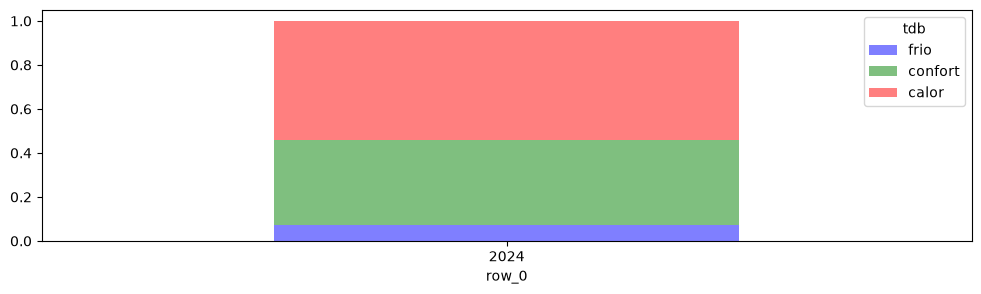

In [23]:
#| label: fig-disconfort-barras
#| fig-cap: "Fracción de horas del año promedio en frío, confort y calor como barra apilada: 7 %, 39 % y 54 %. La etiqueta `row_0` del eje horizontal es el nombre por omisión del índice de `crosstab`."
#| fig-alt: "Una sola barra apilada que llega a 1, con una franja azul delgada abajo, verde en medio y roja arriba que ocupa más de la mitad; leyenda con frio, confort y calor."
fig, axs = plt.subplots(figsize=(12,3))

pct.plot(kind="bar",stacked=True,ax=axs,color=["blue","green","red"],alpha=0.5)

Otra vez la tabla, para compararla con la barra.

In [24]:
pct

tdb,frio,confort,calor
row_0,,,
2024,0.071038,0.38684,0.542122


El primer instante del índice, que usamos como extremo izquierdo de las líneas.

In [25]:
esolmet.index[0]

Timestamp('2024-01-01 00:00:00')

## La serie con las dos líneas de confort

`ax.hlines(y, xmin, xmax)` dibuja una línea horizontal; las dos marcan 18 y 23 °C. Los
extremos se obtienen de dos formas equivalentes: `index[0]` y `index[-1]`, o `index.min()`
y `index.max()`. Con la serie encima se ve de dónde sale el 54 % de calor: de marzo a
junio casi todas las horas están por encima de 23 °C.

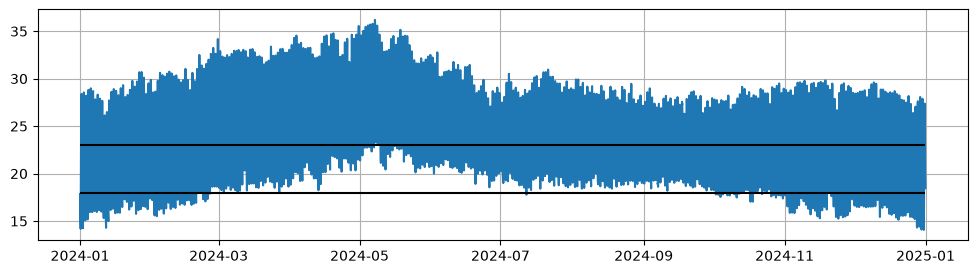

In [26]:
#| label: fig-disconfort-lineas
#| fig-cap: "Temperatura horaria del año promedio con las líneas de 18 y 23 °C. De marzo a junio casi todas las horas quedan por encima de la línea de confort."
#| fig-alt: "Serie azul densa que oscila entre 15 y 36 grados a lo largo de 2024 con dos líneas horizontales negras en 18 y 23; la serie sube por encima de ambas entre marzo y junio."
fig, ax = plt.subplots(figsize=(12,3))

ax.plot(esolmet.tdb)
ax.hlines(18,esolmet.index[0],esolmet.index[-1],color="k")
ax.hlines(23,esolmet.index.min(),esolmet.index.max(),color="k")
ax.grid()

## Comprobar con máscaras booleanas

Tres comparaciones producen tres máscaras; `esolmet[frio_mask]` se queda con las horas
frías, y así con las otras dos. Dibujar cada subconjunto como puntos de un color reproduce
las categorías de `cut` sin usarlo: la figura debe coincidir con la barra apilada.

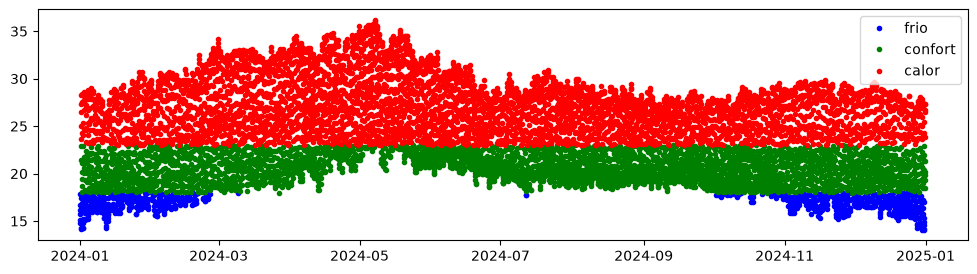

In [27]:
#| label: fig-disconfort-mascaras
#| fig-cap: "Las mismas horas pintadas por categoría con máscaras booleanas: azul frío, verde confort, rojo calor. La imagen reproduce las fracciones de la barra apilada."
#| fig-alt: "Nube de puntos de 2024 dividida en tres bandas horizontales de color: azul debajo de 18 grados, verde entre 18 y 23, rojo arriba de 23; la banda roja es la más ancha."
frio_mask = esolmet.tdb < 18
confort_mask = (esolmet.tdb >= 18) & (esolmet.tdb <=23)
calor_mask = esolmet.tdb > 23

fig, ax = plt.subplots(figsize=(12,3))

ax.plot(esolmet[frio_mask].tdb,"b.",label="frio")
ax.plot(esolmet[confort_mask].tdb,"g.",label="confort")
ax.plot(esolmet[calor_mask].tdb,"r.",label="calor")

ax.legend()

Total de horas del año promedio.

In [28]:
len(esolmet)

8784

## La fracción de frío a mano

Horas frías entre horas totales: 0.071, el mismo número que dio `crosstab`.

In [29]:
len(esolmet[frio_mask])/len(esolmet)

0.07103825136612021

La tabla de `crosstab`, para confirmar la coincidencia.

In [30]:
pct

tdb,frio,confort,calor
row_0,,,
2024,0.071038,0.38684,0.542122


Celda vacía que quedó al final de la clase.